/Users/Vanshika/Documents/NSUT/DSA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps | models: ['efficientnet_b2', 'resnet50']
HAM10000 usable images: 10015
label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
train 7153 | val 1431 | test 1431  (no shared lesions)

TRAINING efficientnet_b2


/var/folders/8v/blbrt1150g38htb5ctjw2sr00000gn/T/ipykernel_97259/3714479836.py:156: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[efficientnet_b2] ep 01/50 loss 1.6644 | val acc 0.6583 bal_acc 0.5277 | 137s *saved*
[efficientnet_b2] ep 02/50 loss 1.0225 | val acc 0.7449 bal_acc 0.5924 | 122s *saved*
[efficientnet_b2] ep 03/50 loss 0.8673 | val acc 0.7771 bal_acc 0.6491 | 129s *saved*
[efficientnet_b2] ep 04/50 loss 0.7937 | val acc 0.7966 bal_acc 0.6642 | 142s *saved*
[efficientnet_b2] ep 05/50 loss 0.7484 | val acc 0.7771 bal_acc 0.6793 | 147s *saved*
[efficientnet_b2] ep 06/50 loss 0.6929 | val acc 0.8050 bal_acc 0.6856 | 125s *saved*
[efficientnet_b2] ep 07/50 loss 0.6657 | val acc 0.8120 bal_acc 0.6974 | 126s *saved*
[efficientnet_b2] ep 08/50 loss 0.6411 | val acc 0.8148 bal_acc 0.6942 | 127s
[efficientnet_b2] ep 09/50 loss 0.6138 | val acc 0.8246 bal_acc 0.7164 | 127s *saved*
[efficientnet_b2] ep 10/50 loss 0.6034 | val acc 0.8085 bal_acc 0.6928 | 129s
[efficientnet_b2] ep 11/50 loss 0.5798 | val acc 0.8288 bal_acc 0.7176 | 127s *saved*
[efficientnet_b2] ep 12/50 loss 0.5689 | val acc 0.8232 bal_acc 0.7114

/var/folders/8v/blbrt1150g38htb5ctjw2sr00000gn/T/ipykernel_97259/3714479836.py:156: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[resnet50] ep 01/50 loss 1.6128 | val acc 0.6932 bal_acc 0.2316 | 120s *saved*
[resnet50] ep 02/50 loss 1.3261 | val acc 0.7568 bal_acc 0.5497 | 118s *saved*
[resnet50] ep 03/50 loss 1.1210 | val acc 0.7792 bal_acc 0.6416 | 118s *saved*
[resnet50] ep 04/50 loss 0.9863 | val acc 0.7764 bal_acc 0.7149 | 116s *saved*
[resnet50] ep 05/50 loss 0.9067 | val acc 0.7855 bal_acc 0.7164 | 116s *saved*
[resnet50] ep 06/50 loss 0.8452 | val acc 0.8036 bal_acc 0.7084 | 117s
[resnet50] ep 07/50 loss 0.8222 | val acc 0.7973 bal_acc 0.7405 | 119s *saved*
[resnet50] ep 08/50 loss 0.8050 | val acc 0.8155 bal_acc 0.7352 | 114s
[resnet50] ep 09/50 loss 0.7689 | val acc 0.8008 bal_acc 0.7368 | 116s
[resnet50] ep 10/50 loss 0.7566 | val acc 0.8309 bal_acc 0.7347 | 116s
[resnet50] ep 11/50 loss 0.7292 | val acc 0.8162 bal_acc 0.7415 | 115s *saved*
[resnet50] ep 12/50 loss 0.7049 | val acc 0.8120 bal_acc 0.7442 | 115s *saved*
[resnet50] ep 13/50 loss 0.6880 | val acc 0.8148 bal_acc 0.7375 | 115s
[resnet50] ep

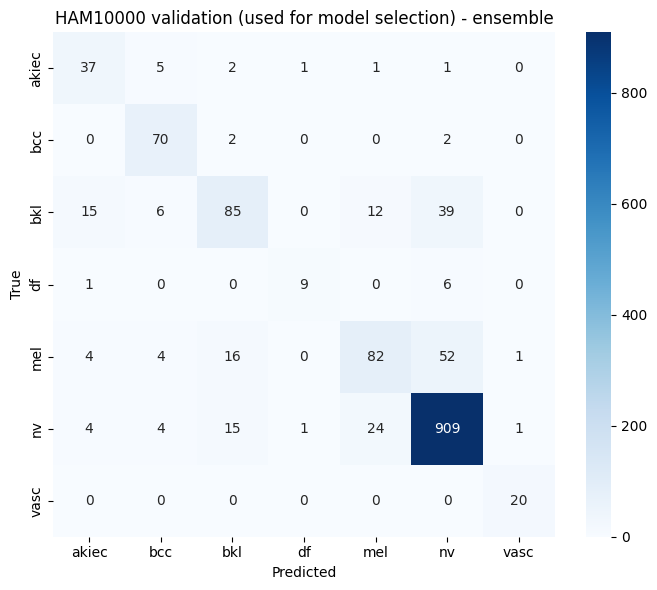

In [1]:
# ===================== CELL 1: TRAIN ON HAM10000 =====================
# pip install torch torchvision timm pandas numpy scikit-learn matplotlib seaborn pillow
# Run this notebook from inside "CV Lab Project/" (the folder that contains data/).
#
# Leakage controls:
#  * HAM10000 is split into train / val / test BY lesion_id (stratified), so the same
#    lesion never appears in two partitions.
#  * Only the train split is augmented / oversampled.
#  * Model selection (best epoch) uses val only. The ensemble is a plain average (no tuned
#    weights, multipliers or thresholds), so nothing is tuned on any test data.
#  * Test sets (cells 2 and 3) are used only for final evaluation.

import os, time, random
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

# ------------------------- config -------------------------
TAG = "nb2_effnet_resnet50"
MODEL_NAMES = ['efficientnet_b2', 'resnet50']          # timm model names
LR = {"swin_tiny_patch4_window7_224": 5e-5, "convnext_tiny": 5e-5}   # default 1e-4
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
NUM_CLASSES = len(CLASSES)
IMG = 224
BATCH = 32
EPOCHS = 50
PATIENCE = 10                      # early stop if val balanced acc does not improve for 10 epochs
SEED = 42

BASE = Path.cwd()
DATA = BASE / "data"
HAM_CSV = DATA / "HAM10000_metadata.csv"
HAM_IMGS = DATA / "images"
ISIC_DIR = DATA / "ISIC2019_Dataset"
MODEL_DIR = BASE / "models"; MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR = BASE / "research_results"; OUT_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
NUM_WORKERS = 4 if DEVICE.type == "cuda" else 0
print("Device:", DEVICE, "| models:", MODEL_NAMES)

# ------------------------- data frames -------------------------
def build_ham_df():
    ham = pd.read_csv(HAM_CSV)
    paths = {p.stem: str(p) for p in HAM_IMGS.rglob("*.jpg")}
    ham = ham[ham["image_id"].isin(paths)].copy()
    ham["path"] = ham["image_id"].map(paths)
    ham["label"] = ham["dx"]
    ham["group"] = ham["lesion_id"].astype(str)
    ham["y"] = ham["label"].map({c: i for i, c in enumerate(CLASSES)})
    return ham[["image_id", "path", "label", "group", "y"]].reset_index(drop=True)

ISIC_FOLDER_TO_DX = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df",
                     "MEL": "mel", "NV": "nv", "VASC": "vasc"}   # SCC is not in the 7-class space

def build_isic_df():
    rows = []
    for folder, dx in ISIC_FOLDER_TO_DX.items():
        for p in (ISIC_DIR / folder).rglob("*.jpg"):
            rows.append((p.stem, str(p), dx))
    df = pd.DataFrame(rows, columns=["image_id", "path", "label"])
    df["y"] = df["label"].map({c: i for i, c in enumerate(CLASSES)})
    return df

_ISIC_CACHE = {}
def get_isic_deduped():
    # ISIC2019 contains the HAM10000 images -> remove them by image id so that no image
    # the models were trained on shows up in the ISIC test set.
    if "df" not in _ISIC_CACHE:
        isic = build_isic_df()
        n0 = len(isic)
        isic = isic[~isic["image_id"].isin(set(ham_all["image_id"]))].reset_index(drop=True)
        print(f"ISIC2019: {n0} images -> {len(isic)} after removing {n0 - len(isic)} HAM10000 duplicates")
        _ISIC_CACHE["df"] = isic
    return _ISIC_CACHE["df"]

ham_all = build_ham_df()
print("HAM10000 usable images:", len(ham_all)); print(ham_all["label"].value_counts())

# lesion-grouped, stratified 3-way split
sg1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_idx, test_idx = next(sg1.split(ham_all, ham_all["y"], ham_all["group"]))
trval, test_df = ham_all.iloc[trval_idx].reset_index(drop=True), ham_all.iloc[test_idx].reset_index(drop=True)
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sg2.split(trval, trval["y"], trval["group"]))
train_df, val_df = trval.iloc[tr_idx].reset_index(drop=True), trval.iloc[va_idx].reset_index(drop=True)
assert not (set(train_df.group) & set(val_df.group)) and not (set(train_df.group) & set(test_df.group)) \
    and not (set(val_df.group) & set(test_df.group)), "lesion leakage!"
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}  (no shared lesions)")
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(OUT_DIR / f"{TAG}_ham_{n}_split.csv", index=False)

# ------------------------- preprocessing / datasets -------------------------
def shades_of_gray(img, p=6):          # colour constancy -> helps cross-dataset transfer
    x = np.asarray(img, dtype=np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p) + 1e-6
    illum = illum / np.linalg.norm(illum)
    x = x / (illum * np.sqrt(3.0))
    return Image.fromarray(np.clip(x, 0, 255).astype(np.uint8))

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.85, 1.15), shear=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor()])
eval_tf = transforms.ToTensor()

class LesionDS(Dataset):
    def __init__(self, df, train):
        self.paths, self.y, self.tf = df["path"].tolist(), df["y"].values, (train_tf if train else eval_tf)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB").resize((IMG, IMG), Image.BILINEAR)
        return self.tf(shades_of_gray(img)), int(self.y[i])

counts = train_df["y"].value_counts().reindex(range(NUM_CLASSES)).values.astype(float)
sample_w = (1.0 / np.sqrt(counts))[train_df["y"].values]      # mild minority oversampling, train only
sampler = WeightedRandomSampler(sample_w, num_samples=len(train_df), replacement=True)
train_loader = DataLoader(LesionDS(train_df, True), BATCH, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(LesionDS(val_df, False), BATCH, num_workers=NUM_WORKERS)

# ------------------------- models -------------------------
class Wrapped(nn.Module):
    # takes [0,1] images, applies each backbone's own ImageNet normalisation
    def __init__(self, name):
        super().__init__()
        self.m = timm.create_model(name, pretrained=True, num_classes=NUM_CLASSES)
        cfg = timm.data.resolve_data_config({}, model=self.m)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1))
    def forward(self, x): return self.m((x - self.mean) / self.std)

@torch.no_grad()
def predict_loader(model, loader):
    model.eval(); out = []
    for x, _ in loader:
        out.append(F.softmax(model(x.to(DEVICE)).float(), 1).cpu().numpy())
    return np.concatenate(out)

def train_model(name):
    model = Wrapped(name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR.get(name, 1e-4), weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, bad, ckpt = -1, 0, MODEL_DIR / f"{TAG}_{name}.pth"
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, run = time.time(), 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type="cuda", enabled=use_amp):
                loss = F.cross_entropy(model(x), y, label_smoothing=0.1)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * x.size(0)
        sched.step()
        pv = predict_loader(model, val_loader)
        bal = balanced_accuracy_score(val_df["y"].values, pv.argmax(1))    # selection metric (val only)
        acc = accuracy_score(val_df["y"].values, pv.argmax(1))
        flag = ""
        if bal > best:
            best, bad, flag = bal, 0, " *saved*"; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"[{name}] ep {ep:02d}/{EPOCHS} loss {run/len(train_df):.4f} | val acc {acc:.4f} bal_acc {bal:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad >= PATIENCE:
            print("early stop"); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.eval()
    return model

MODELS = {}
for n in MODEL_NAMES:
    print("\n" + "=" * 70 + f"\nTRAINING {n}\n" + "=" * 70)
    MODELS[n] = train_model(n)

# ------------------------- shared inference / reporting helpers -------------------------
def get_probs(df):
    loader = DataLoader(LesionDS(df, False), BATCH, num_workers=NUM_WORKERS)
    return {n: predict_loader(m, loader) for n, m in MODELS.items()}

def report(title, y, P):
    ens = np.mean([P[n] for n in MODEL_NAMES], axis=0)
    allp = dict(P); allp["ENSEMBLE (mean)"] = ens
    rows = [dict(model=n, acc=accuracy_score(y, p.argmax(1)), balanced_acc=balanced_accuracy_score(y, p.argmax(1)),
                 macro_f1=f1_score(y, p.argmax(1), average="macro", zero_division=0)) for n, p in allp.items()]
    print("\n" + "=" * 70 + f"\n{title}  (n={len(y)})\n" + "=" * 70)
    print(pd.DataFrame(rows).round(4).to_string(index=False))
    names = list(P)                     # complementarity: lower double-fault = more complementary
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            wi, wj = P[names[i]].argmax(1) != y, P[names[j]].argmax(1) != y
            print(f"double-fault {names[i]} & {names[j]}: {(wi & wj).mean():.4f} | disagreement: "
                  f"{(P[names[i]].argmax(1) != P[names[j]].argmax(1)).mean():.4f}")
    pred = ens.argmax(1)
    print("\nEnsemble classification report:")
    print(classification_report(y, pred, labels=range(NUM_CLASSES), target_names=CLASSES, digits=3, zero_division=0))
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    plt.figure(figsize=(7, 6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(f"{title} - ensemble"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    safe = "".join(ch if ch.isalnum() else "_" for ch in title)
    plt.savefig(OUT_DIR / f"{TAG}_{safe}_cm.png", dpi=150); plt.show()

# validation sanity check (this set is used for epoch selection, so it is NOT a test result)
PV = get_probs(val_df)
report("HAM10000 validation (used for model selection)", val_df["y"].values, PV)


ISIC2019: 24703 images -> 14885 after removing 9818 HAM10000 duplicates
label
nv       6170
mel      3409
bcc      2809
bkl      1525
akiec     737
df        124
vasc      111
Name: count, dtype: int64

ISIC2019 external test (HAM-trained)  (n=14885)
          model    acc  balanced_acc  macro_f1
efficientnet_b2 0.5855        0.4070    0.4026
       resnet50 0.5734        0.4134    0.3950
ENSEMBLE (mean) 0.6074        0.4318    0.4270
double-fault efficientnet_b2 & resnet50: 0.3012 | disagreement: 0.3444

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.205     0.227     0.215       737
         bcc      0.734     0.483     0.583      2809
         bkl      0.347     0.407     0.374      1525
          df      0.155     0.242     0.189       124
         mel      0.694     0.402     0.509      3409
          nv      0.670     0.884     0.762      6170
        vasc      0.336     0.378     0.356       111

    accuracy           

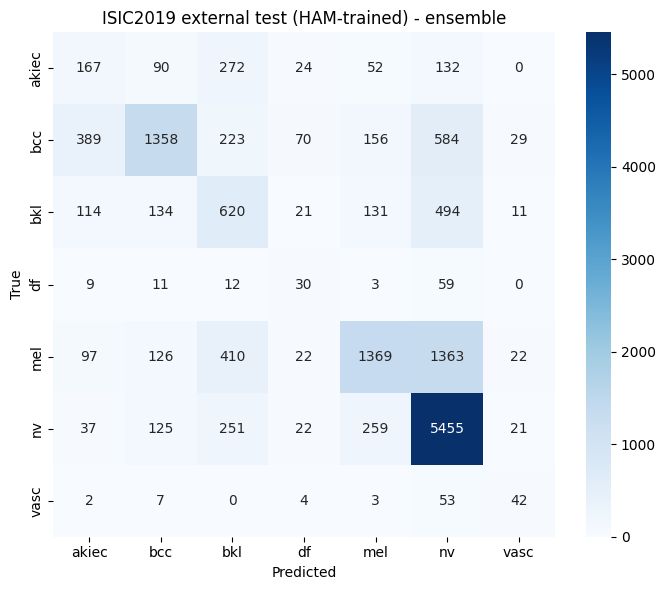

In [2]:
# ===================== CELL 2: TEST ON ISIC2019 (external dataset) =====================
# Models were trained only on the HAM10000 train split. ISIC2019 images that are also in
# HAM10000 are removed, so this is a true cross-dataset test (domain shift is expected).
isic_df = get_isic_deduped()
print(isic_df["label"].value_counts())
PROBS = globals().setdefault("PROBS", {})
PROBS["isic"] = get_probs(isic_df)
report("ISIC2019 external test (HAM-trained)", isic_df["y"].values, PROBS["isic"])



HAM10000 held-out test (in-dataset)  (n=1431)
          model    acc  balanced_acc  macro_f1
efficientnet_b2 0.8162        0.6030    0.6380
       resnet50 0.8218        0.6515    0.6505
ENSEMBLE (mean) 0.8309        0.6355    0.6628
double-fault efficientnet_b2 & resnet50: 0.1237 | disagreement: 0.1544

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.410     0.543     0.467        46
         bcc      0.639     0.838     0.725        74
         bkl      0.771     0.535     0.632       157
          df      1.000     0.353     0.522        17
         mel      0.692     0.465     0.556       159
          nv      0.893     0.963     0.927       958
        vasc      0.882     0.750     0.811        20

    accuracy                          0.831      1431
   macro avg      0.755     0.635     0.663      1431
weighted avg      0.829     0.831     0.822      1431



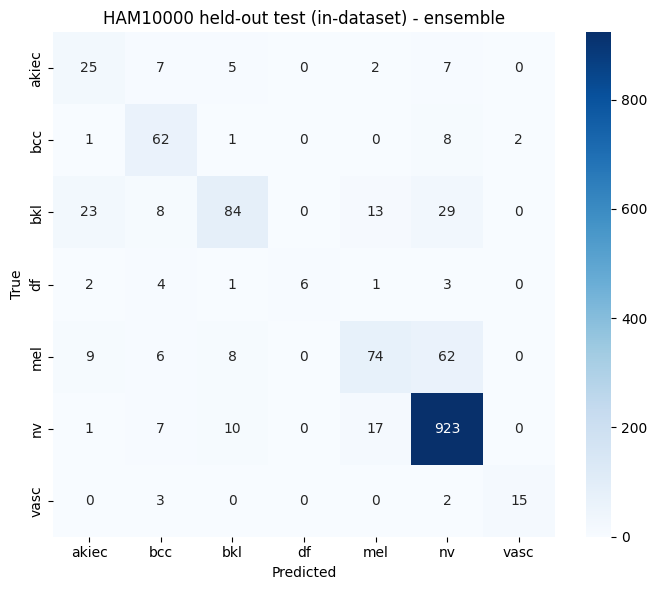


Combined HAM-test + ISIC2019  (n=16316)
          model    acc  balanced_acc  macro_f1
efficientnet_b2 0.6057        0.4251    0.4238
       resnet50 0.5952        0.4351    0.4176
ENSEMBLE (mean) 0.6270        0.4494    0.4479
double-fault efficientnet_b2 & resnet50: 0.2856 | disagreement: 0.3277

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.219     0.245     0.231       783
         bcc      0.729     0.493     0.588      2883
         bkl      0.371     0.419     0.393      1682
          df      0.181     0.255     0.212       141
         mel      0.694     0.404     0.511      3568
          nv      0.695     0.895     0.782      7128
        vasc      0.401     0.435     0.418       131

    accuracy                          0.627     16316
   macro avg      0.470     0.449     0.448     16316
weighted avg      0.638     0.627     0.614     16316



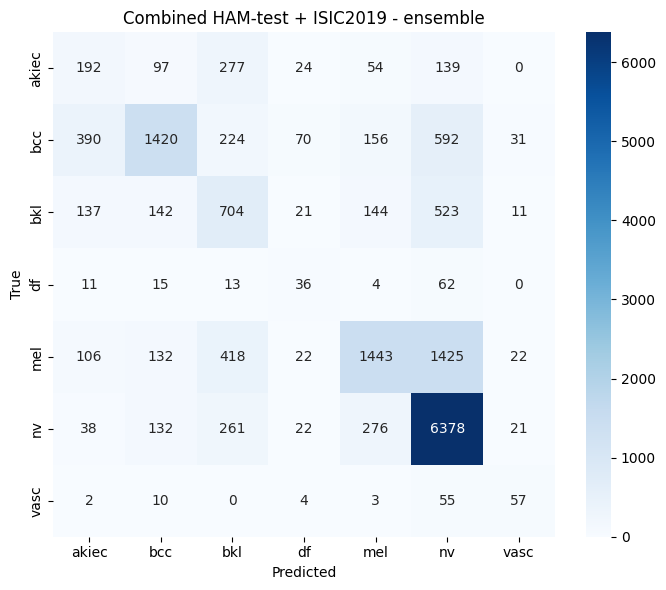

In [3]:
# ===================== CELL 3: TEST ON COMBINED (HAM10000 test split + ISIC2019) =====================
# HAM part  = held-out, lesion-disjoint test split only (never used in training/validation).
# ISIC part = ISIC2019 minus HAM10000 duplicates.
PROBS = globals().setdefault("PROBS", {})
isic_df = get_isic_deduped()
if "isic" not in PROBS:
    PROBS["isic"] = get_probs(isic_df)
PROBS["ham_test"] = get_probs(test_df)

report("HAM10000 held-out test (in-dataset)", test_df["y"].values, PROBS["ham_test"])

y_comb = np.concatenate([test_df["y"].values, isic_df["y"].values])
P_comb = {n: np.concatenate([PROBS["ham_test"][n], PROBS["isic"][n]]) for n in MODEL_NAMES}
report("Combined HAM-test + ISIC2019", y_comb, P_comb)


/Users/Vanshika/Documents/NSUT/DSA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project folder: /Users/Vanshika/Documents/CV Lab Project
loaded: ['efficientnet_b2', 'resnet50']


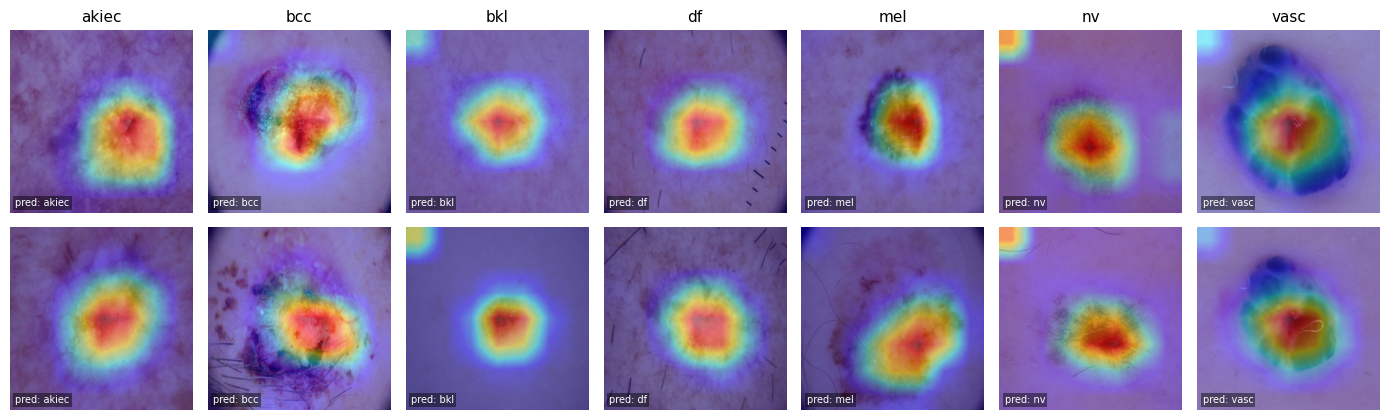

saved: /Users/Vanshika/Documents/CV Lab Project/research_results/gradcam_final_ham.png


In [2]:
# ===================== Grad-CAM FOR THE FINAL ENSEMBLE - STANDALONE CELL =====================
# Works in a FRESH kernel: it does NOT retrain. It reloads the checkpoints saved by the training cell
#   models/nb2_effnet_resnet50_efficientnet_b2.pth   and   models/nb2_effnet_resnet50_resnet50.pth
# and the test split saved at research_results/nb2_effnet_resnet50_ham_test_split.csv (same images as in the paper).
# pip install torch torchvision timm pandas numpy matplotlib pillow
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

PROJECT_DIR = None          # e.g. "/Users/Vanshika/Documents/CV Lab Project"; None = auto-detect
GRADCAM_SET = "ham"         # "ham" = HAM10000 held-out test split | "isic" = external ISIC2019 images
SELECT      = "correct"     # "correct" = first N correctly classified images per class | "first" = first N, right or wrong
N_PER_CLASS = 2
TAG         = "nb2_effnet_resnet50"
MODEL_NAMES = ["efficientnet_b2", "resnet50"]
CLASSES     = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
IMG         = 224

def find_base():
    if PROJECT_DIR: return Path(PROJECT_DIR).expanduser()
    marker = Path("data") / "HAM10000_metadata.csv"
    cwd = Path.cwd()
    for c in [cwd, *cwd.parents]:
        if (c / marker).exists(): return c
        if (c / "CV Lab Project" / marker).exists(): return c / "CV Lab Project"
    for root in (Path.home() / "Documents", Path.home() / "Downloads", Path.home() / "Desktop", Path.home()):
        for pat in ("*/", "*/*/", "*/*/*/"):
            for d in root.glob(pat):
                if (d / marker).exists(): return d
    raise FileNotFoundError("Could not find data/HAM10000_metadata.csv - set PROJECT_DIR above.")
BASE = find_base(); print("Project folder:", BASE)
MODEL_DIR, OUT_DIR, ISIC_DIR = BASE / "models", BASE / "research_results", BASE / "data" / "ISIC2019_Dataset"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

# ---- same pre-processing and model wrapper as the training cell
def shades_of_gray(img, p=6):
    x = np.asarray(img, dtype=np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p) + 1e-6
    illum = illum / np.linalg.norm(illum)
    return Image.fromarray(np.clip(x / (illum * np.sqrt(3.0)), 0, 255).astype(np.uint8))
eval_tf = transforms.ToTensor()

class Wrapped(nn.Module):
    def __init__(self, name):
        super().__init__()
        self.m = timm.create_model(name, pretrained=False, num_classes=len(CLASSES))   # weights come from the checkpoint
        cfg = timm.data.resolve_data_config({}, model=self.m)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1))
    def forward(self, x): return self.m((x - self.mean) / self.std)

MODELS = {}
for n in MODEL_NAMES:
    m = Wrapped(n).to(DEVICE)
    m.load_state_dict(torch.load(MODEL_DIR / f"{TAG}_{n}.pth", map_location=DEVICE)); MODELS[n] = m.eval()
print("loaded:", list(MODELS))

# ---- image set
split = lambda s: pd.read_csv(OUT_DIR / f"{TAG}_ham_{s}_split.csv")
if GRADCAM_SET == "ham":
    frame = split("test")
else:                                              # ISIC2019 minus every HAM10000 image (same dedupe as the notebook)
    ham_ids = set(pd.concat([split("train"), split("val"), split("test")])["image_id"])
    dx = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df", "MEL": "mel", "NV": "nv", "VASC": "vasc"}
    frame = pd.DataFrame([(p.stem, str(p), d) for f, d in dx.items() for p in (ISIC_DIR / f).rglob("*.jpg")],
                         columns=["image_id", "path", "label"])
    frame = frame[~frame["image_id"].isin(ham_ids)].reset_index(drop=True)

# ---- Grad-CAM
def _target_layer(name, model):
    return model.m.bn2 if name == "efficientnet_b2" else model.m.layer4

def _load(path):
    img = Image.open(path).convert("RGB").resize((IMG, IMG), Image.BILINEAR)
    return img, eval_tf(shades_of_gray(img)).unsqueeze(0).to(DEVICE)

def _cam(name, model, x, cls):
    store = {}
    def fwd_hook(m, i, o):                         # must return None, otherwise it would replace the layer output
        store["a"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    h = _target_layer(name, model).register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad(set_to_none=True)
    with torch.enable_grad():
        logits = model(x.clone().requires_grad_(True)); logits[0, cls].backward()
    h.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, (IMG, IMG), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def _ens_probs(x):
    with torch.no_grad():
        return np.mean([F.softmax(MODELS[n](x).float(), 1).cpu().numpy()[0] for n in MODEL_NAMES], axis=0)

fig, axs = plt.subplots(N_PER_CLASS, len(CLASSES), figsize=(2.0 * len(CLASSES), 2.0 * N_PER_CLASS + 0.4))
for j, cls in enumerate(CLASSES):
    picked = []
    for _, r in frame[frame["label"] == cls].head(60 if SELECT == "correct" else N_PER_CLASS).iterrows():
        img, x = _load(r["path"]); pred = int(_ens_probs(x).argmax())
        if SELECT == "first" or pred == j: picked.append((img, x, pred))
        if len(picked) == N_PER_CLASS: break
    for i in range(N_PER_CLASS):
        ax = axs[i, j]; ax.axis("off")
        if i < len(picked):
            img, x, pred = picked[i]
            cam = np.mean([_cam(n, MODELS[n], x, pred) for n in MODEL_NAMES], axis=0)   # ensemble-predicted class
            ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.45)
            ax.text(0.03, 0.04, f"pred: {CLASSES[pred]}", transform=ax.transAxes, fontsize=7, color="white",
                    bbox=dict(facecolor="black", alpha=0.45, pad=1.5, lw=0))
        if i == 0: ax.set_title(cls, fontsize=11)
plt.tight_layout()
out = OUT_DIR / f"gradcam_final_{GRADCAM_SET}.png"
plt.savefig(out, dpi=300, bbox_inches="tight"); plt.show(); print("saved:", out)
